# 5.1 Estimation quality on the reference dataset

Here we use only test subset and results estimated earlier in the notebook #4.1.

In [1]:
import os
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

from common.configuration import DatasetPath, species_classes_map_all, species_by_familia, species_by_ordo, species_invasive

Load dataset and replace invasive labels with "Unknown", which is an estimated response.

In [2]:
predictions_path = "Save/reference_predictions.csv"
model_prediction_df = pd.read_csv(predictions_path, index_col=0).fillna(0)
model_prediction_df["label"] = model_prediction_df["label"].map(lambda x: "Unknown" if x in species_invasive else x)
model_prediction_df


,label,prediction,embeddings,image
0,Acer,Acer,[ 4.396412 0.2449137 -0.80762184 2.078964...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
1,Acer,Acer,[ 6.5362225 1.0517198 -1.3801564 1.075449...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
2,Acer,Acer,[ 5.9718475 -0.38173628 -0.6895616 0.739156...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
3,Acer,Acer,[ 6.712505 0.6844996 -1.435263 1.068408...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
4,Acer,Acer,[ 7.573977 0.03823689 -0.55947745 0.832285...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
...,...,...,...,...
1430,Unknown,Acer,[ 4.698799 2.4068203 -0.41649652 0.169760...,Dataset/pollen_dataset_2025_02_05\samples/Malu...
1431,Unknown,Acer,[ 5.3533034 1.470593 0.31046188 -1.670055...,Dataset/pollen_dataset_2025_02_05\samples/Malu...
1432,Unknown,Acer,[ 4.9781733 1.9623456 -0.5365845 -0.655493...,Dataset/pollen_dataset_2025_02_05\samples/Malu...
1433,Unknown,Acer,[ 4.8460608 -1.0959177 -1.1885815 -0.352981...,Dataset/pollen_dataset_2025_02_05\samples/Malu...


## Quality on Genus level

In [3]:
possible_labels = list(set(pd.unique(model_prediction_df["label"])) | set(pd.unique(model_prediction_df["prediction"])))
possible_labels.sort()
possible_labels.append(possible_labels.pop(possible_labels.index("Unknown")))
possible_labels

['Acer',
 'Alnus',
 'Ambrosia',
 'Apiaceae',
 'Artemisia',
 'Betula',
 'Chenopodiaceae',
 'Corylus',
 'Picea',
 'Pinus',
 'Plantago',
 'Poaceae',
 'Populus tremula',
 'Quercus',
 'Rumex',
 'Salix',
 'Tilia',
 'Ulmus',
 'Urtica',
 'Unknown']

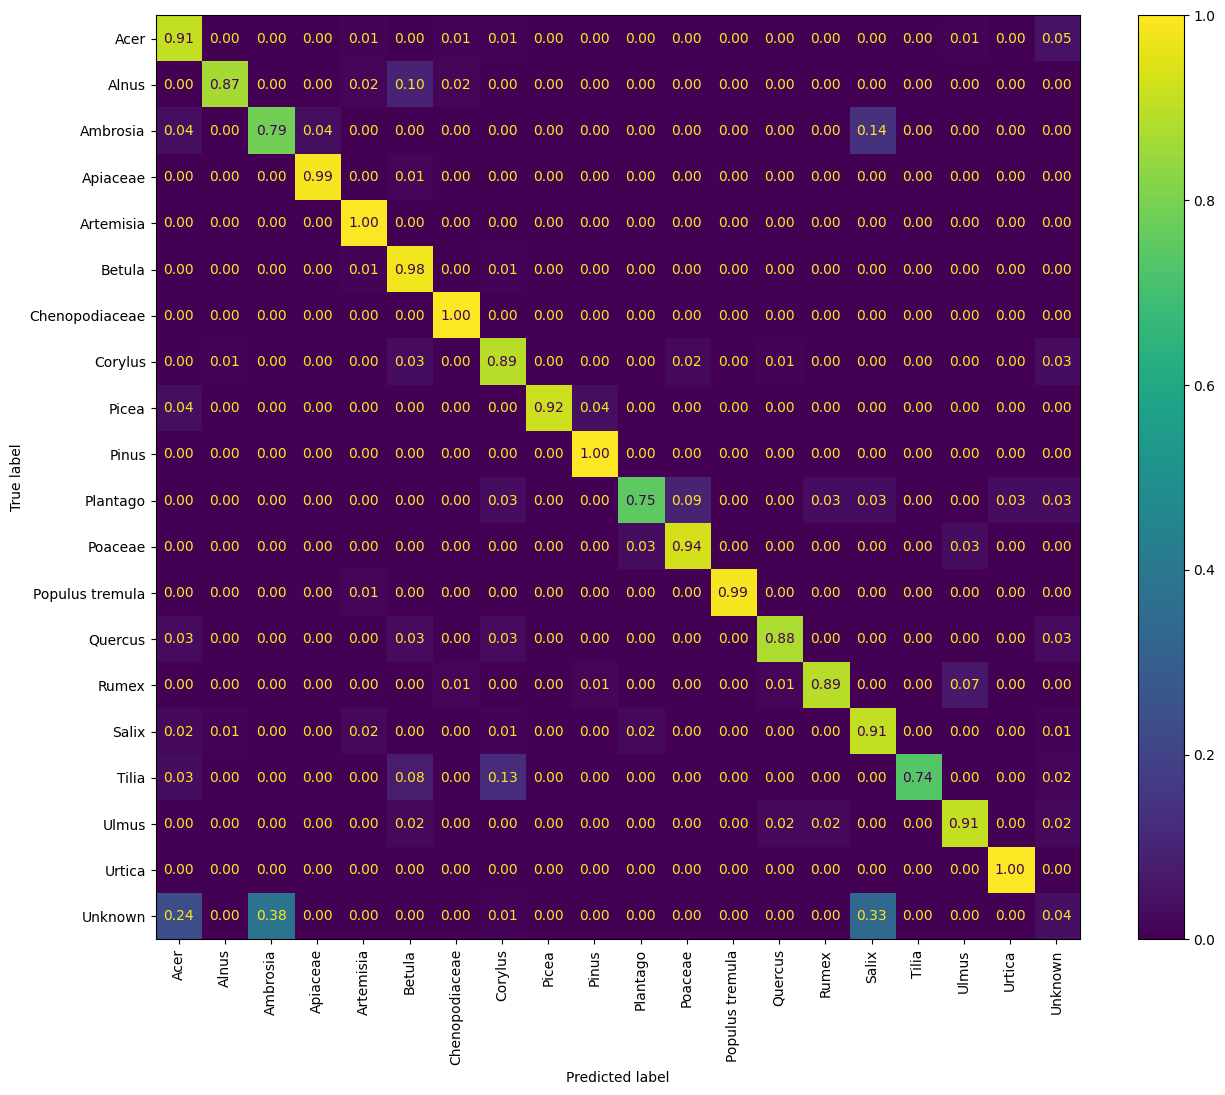

In [4]:
fig, ax = plt.subplots(figsize=(15,12))
cm = confusion_matrix(model_prediction_df["label"], model_prediction_df["prediction"], labels=possible_labels)
disp = ConfusionMatrixDisplay.from_predictions(
    model_prediction_df["label"], 
    model_prediction_df["prediction"], 
    labels=possible_labels, 
    display_labels=possible_labels,
    xticks_rotation="vertical",
    normalize="true",
    values_format=".2f",
    ax=ax)
plt.savefig("Save/images/confusion_matrix_reference_ds.svg")

In [5]:
print(classification_report(model_prediction_df["label"], model_prediction_df["prediction"], labels=possible_labels))

                 precision    recall  f1-score   support

           Acer       0.75      0.91      0.82       100
          Alnus       0.96      0.87      0.91        52
       Ambrosia       0.36      0.79      0.49        28
       Apiaceae       0.99      0.99      0.99        82
      Artemisia       0.90      1.00      0.95        52
         Betula       0.86      0.98      0.92        99
 Chenopodiaceae       0.98      1.00      0.99       192
        Corylus       0.85      0.89      0.87        92
          Picea       1.00      0.92      0.96        26
          Pinus       0.94      1.00      0.97        34
       Plantago       0.89      0.75      0.81        32
        Poaceae       0.85      0.94      0.89        31
Populus tremula       1.00      0.99      0.99        80
        Quercus       0.91      0.88      0.89        33
          Rumex       0.97      0.89      0.93        75
          Salix       0.70      0.91      0.79       100
          Tilia       1.00    

## Quality on Family level

Firstly we need to add collumn with label and predicted familia.

In [6]:
label_to_familia = { v: k for k, l in species_by_familia.items() for v in l }
label_to_familia["Unknown"] = "Unknown"
label_to_familia

{'Acer': 'Sapindaceae',
 'Alnus': 'Betulaceae',
 'Betula': 'Betulaceae',
 'Corylus': 'Betulaceae',
 'Ulmus': 'Ulmaceae',
 'Quercus': 'Fagaceae',
 'Salix': 'Salicaceae',
 'Populus tremula': 'Salicaceae',
 'Tilia': 'Malvaceae',
 'Pinus': 'Pinaceae',
 'Picea': 'Pinaceae',
 'Apiaceae': 'Apiaceae',
 'Artemisia': 'Asteraceae',
 'Ambrosia': 'Asteraceae',
 'Taraxacum': 'Asteraceae',
 'Malus': 'Rosaceae',
 'Poaceae': 'Poaceae',
 'Chenopodiaceae': 'Chenopodiaceae',
 'Plantago': 'Plantaginaceae',
 'Rumex': 'Polygonaceae',
 'Urtica': 'Urticaceae',
 'Unknown': 'Unknown'}

In [7]:
model_prediction_df["familia_label"] = model_prediction_df["label"].map(lambda x: label_to_familia[x])
model_prediction_df["familia_prediction"] = model_prediction_df["prediction"].map(lambda x: label_to_familia[x])
model_prediction_df

,label,prediction,embeddings,image,familia_label,familia_prediction
0,Acer,Acer,[ 4.396412 0.2449137 -0.80762184 2.078964...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae
1,Acer,Acer,[ 6.5362225 1.0517198 -1.3801564 1.075449...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae
2,Acer,Acer,[ 5.9718475 -0.38173628 -0.6895616 0.739156...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae
3,Acer,Acer,[ 6.712505 0.6844996 -1.435263 1.068408...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae
4,Acer,Acer,[ 7.573977 0.03823689 -0.55947745 0.832285...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae
...,...,...,...,...,...,...
1430,Unknown,Acer,[ 4.698799 2.4068203 -0.41649652 0.169760...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae
1431,Unknown,Acer,[ 5.3533034 1.470593 0.31046188 -1.670055...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae
1432,Unknown,Acer,[ 4.9781733 1.9623456 -0.5365845 -0.655493...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae
1433,Unknown,Acer,[ 4.8460608 -1.0959177 -1.1885815 -0.352981...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae


In [8]:
possible_familia_labels = list(set(pd.unique(model_prediction_df["familia_label"])) | set(pd.unique(model_prediction_df["familia_prediction"])))
possible_familia_labels.sort()
possible_familia_labels.append(possible_familia_labels.pop(possible_familia_labels.index("Unknown")))
possible_familia_labels

['Apiaceae',
 'Asteraceae',
 'Betulaceae',
 'Chenopodiaceae',
 'Fagaceae',
 'Malvaceae',
 'Pinaceae',
 'Plantaginaceae',
 'Poaceae',
 'Polygonaceae',
 'Salicaceae',
 'Sapindaceae',
 'Ulmaceae',
 'Urticaceae',
 'Unknown']

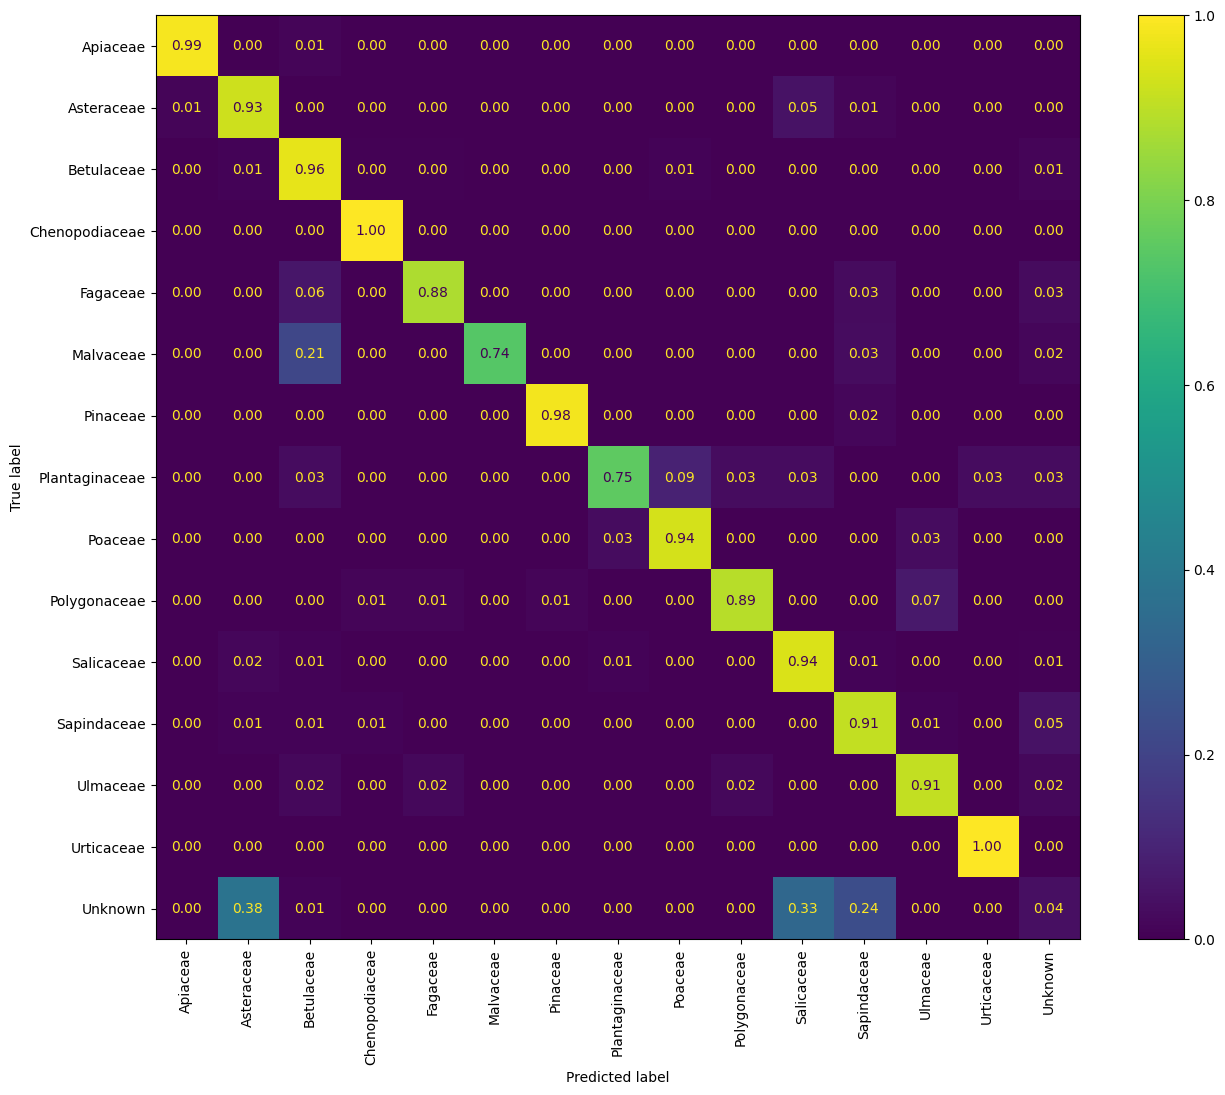

In [9]:
fig, ax = plt.subplots(figsize=(15,12))
cm = confusion_matrix(model_prediction_df["familia_label"], model_prediction_df["familia_prediction"], labels=possible_familia_labels)
disp = ConfusionMatrixDisplay.from_predictions(
    model_prediction_df["familia_label"], 
    model_prediction_df["familia_prediction"], 
    labels=possible_familia_labels, 
    display_labels=possible_familia_labels,
    xticks_rotation="vertical",
    normalize="true",
    values_format=".2f",
    ax=ax)
plt.savefig("Save/images/confusion_matrix_reference_familia_ds.svg")

In [10]:
print(classification_report(model_prediction_df["familia_label"], model_prediction_df["familia_prediction"], labels=possible_familia_labels))

                precision    recall  f1-score   support

      Apiaceae       0.99      0.99      0.99        82
    Asteraceae       0.62      0.93      0.74        80
    Betulaceae       0.91      0.96      0.94       243
Chenopodiaceae       0.98      1.00      0.99       192
      Fagaceae       0.91      0.88      0.89        33
     Malvaceae       1.00      0.74      0.85        61
      Pinaceae       0.98      0.98      0.98        60
Plantaginaceae       0.89      0.75      0.81        32
       Poaceae       0.85      0.94      0.89        31
  Polygonaceae       0.97      0.89      0.93        75
    Salicaceae       0.81      0.94      0.87       180
   Sapindaceae       0.75      0.91      0.82       100
      Ulmaceae       0.85      0.91      0.88        43
    Urticaceae       0.99      1.00      1.00       121
       Unknown       0.24      0.04      0.07       102

      accuracy                           0.88      1435
     macro avg       0.85      0.86      0.84 

## Quality on Order level

In [11]:
label_to_ordo = { v: k for k, l in species_by_ordo.items() for v in l }
label_to_ordo["Unknown"] = "Unknown"
label_to_ordo

{'Acer': 'Sapindales',
 'Alnus': 'Fagales',
 'Betula': 'Fagales',
 'Corylus': 'Fagales',
 'Quercus': 'Fagales',
 'Ulmus': 'Rosales',
 'Malus': 'Rosales',
 'Urtica': 'Rosales',
 'Salix': 'Malpighiales',
 'Populus tremula': 'Malpighiales',
 'Tilia': 'Malvales',
 'Pinus': 'Pinales',
 'Picea': 'Pinales',
 'Apiaceae': 'Apiales',
 'Artemisia': 'Asterales',
 'Ambrosia': 'Asterales',
 'Taraxacum': 'Asterales',
 'Poaceae': 'Poales',
 'Chenopodiaceae': 'Caryophyllales',
 'Rumex': 'Caryophyllales',
 'Plantago': 'Lamiales',
 'Unknown': 'Unknown'}

In [12]:
model_prediction_df["ordo_label"] = model_prediction_df["label"].map(lambda x: label_to_ordo[x])
model_prediction_df["ordo_prediction"] = model_prediction_df["prediction"].map(lambda x: label_to_ordo[x])
model_prediction_df

,label,prediction,embeddings,image,familia_label,familia_prediction,ordo_label,ordo_prediction
0,Acer,Acer,[ 4.396412 0.2449137 -0.80762184 2.078964...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae,Sapindales,Sapindales
1,Acer,Acer,[ 6.5362225 1.0517198 -1.3801564 1.075449...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae,Sapindales,Sapindales
2,Acer,Acer,[ 5.9718475 -0.38173628 -0.6895616 0.739156...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae,Sapindales,Sapindales
3,Acer,Acer,[ 6.712505 0.6844996 -1.435263 1.068408...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae,Sapindales,Sapindales
4,Acer,Acer,[ 7.573977 0.03823689 -0.55947745 0.832285...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae,Sapindales,Sapindales
...,...,...,...,...,...,...,...,...
1430,Unknown,Acer,[ 4.698799 2.4068203 -0.41649652 0.169760...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae,Unknown,Sapindales
1431,Unknown,Acer,[ 5.3533034 1.470593 0.31046188 -1.670055...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae,Unknown,Sapindales
1432,Unknown,Acer,[ 4.9781733 1.9623456 -0.5365845 -0.655493...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae,Unknown,Sapindales
1433,Unknown,Acer,[ 4.8460608 -1.0959177 -1.1885815 -0.352981...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae,Unknown,Sapindales


In [13]:
possible_ordo_labels = list(set(pd.unique(model_prediction_df["ordo_label"])) | set(pd.unique(model_prediction_df["ordo_prediction"])))
possible_ordo_labels.sort()
possible_ordo_labels.append(possible_ordo_labels.pop(possible_ordo_labels.index("Unknown")))
possible_ordo_labels
possible_ordo_labels

['Apiales',
 'Asterales',
 'Caryophyllales',
 'Fagales',
 'Lamiales',
 'Malpighiales',
 'Malvales',
 'Pinales',
 'Poales',
 'Rosales',
 'Sapindales',
 'Unknown']

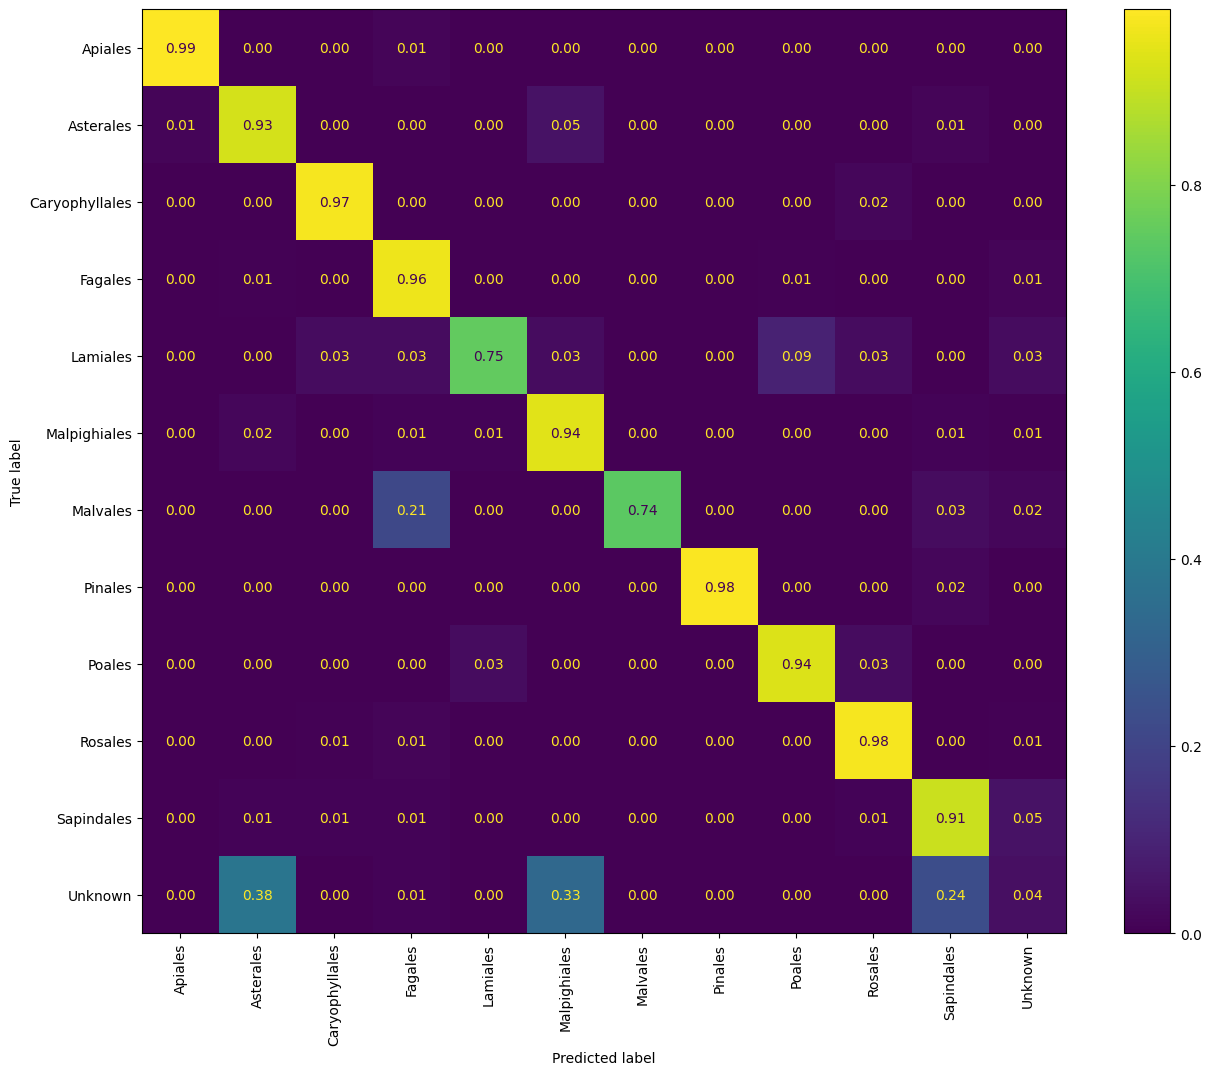

In [14]:
fig, ax = plt.subplots(figsize=(15,12))
cm = confusion_matrix(model_prediction_df["ordo_label"], model_prediction_df["ordo_prediction"], labels=possible_ordo_labels)
disp = ConfusionMatrixDisplay.from_predictions(
    model_prediction_df["ordo_label"], 
    model_prediction_df["ordo_prediction"], 
    labels=possible_ordo_labels, 
    display_labels=possible_ordo_labels,
    xticks_rotation="vertical",
    normalize="true",
    values_format=".2f",
    ax=ax)
plt.savefig("Save/images/confusion_matrix_reference_ordo_ds.svg")

In [15]:
print(classification_report(model_prediction_df["ordo_label"], model_prediction_df["ordo_prediction"], labels=possible_ordo_labels))

                precision    recall  f1-score   support

       Apiales       0.99      0.99      0.99        82
     Asterales       0.62      0.93      0.74        80
Caryophyllales       0.98      0.97      0.98       267
       Fagales       0.92      0.96      0.94       276
      Lamiales       0.89      0.75      0.81        32
  Malpighiales       0.81      0.94      0.87       180
      Malvales       1.00      0.74      0.85        61
       Pinales       0.98      0.98      0.98        60
        Poales       0.85      0.94      0.89        31
       Rosales       0.95      0.98      0.96       164
    Sapindales       0.75      0.91      0.82       100
       Unknown       0.24      0.04      0.07       102

      accuracy                           0.88      1435
     macro avg       0.83      0.84      0.83      1435
  weighted avg       0.85      0.88      0.86      1435

